# Treemap tour

> A set split into subsets, and subsets into sub-subsets, with every member named.

In [ ]:
#| hide
from fastcore.test import *
import tempfile
from pathlib import Path

An Euler diagram shows how sets **overlap**. An itemized treemap shows how one set **divides**:
proteins into complexes, countries into regions, files into folders. Each member gets one cell
with its name in it, each group (at every level) is one rounded shape, and the whole map is a
rectangle, so the figure is also the lookup table.

## A first treemap

The proximity partners of the RNA helicase DDX6, grouped by gene family:

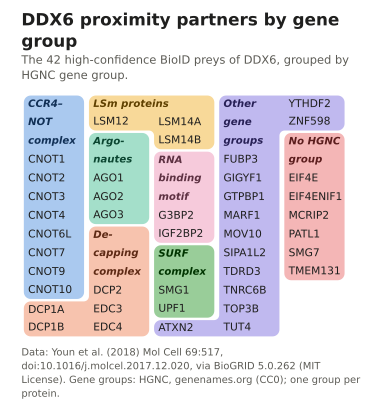

In [ ]:
from itemiset import treemap

lay = treemap.plot(**treemap.load_example("ddx6"))
lay

Each group is one shape in its own colour, with its name (the header) in heavier coloured text.
Headers sit along the top or bottom edge of their group where a whole row is free, so names are
never beside them. The two pooled groups go last: proteins that are the only partner from their
gene group, and proteins HGNC has not put in any group.

## Two levels, and numbers

Groups can nest. Here countries are grouped by continent and then by subregion, and each
carries a number, its population in millions, set in grey before the name and lined up in its
own column:

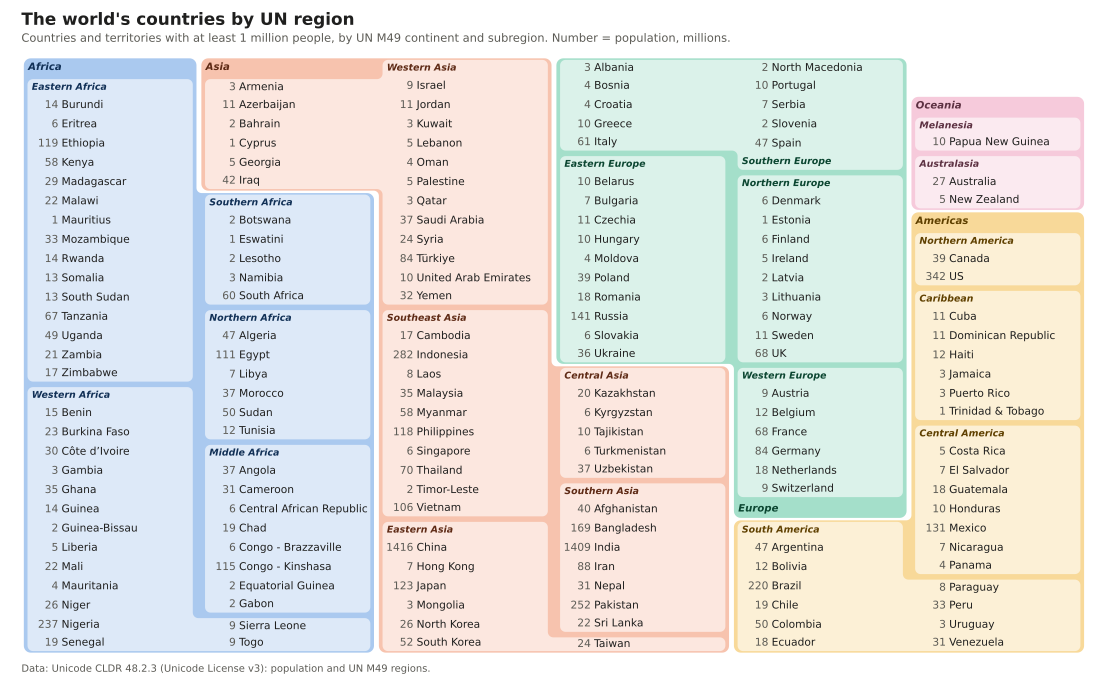

In [ ]:
lay = treemap.plot(**treemap.load_example("countries"))
lay

Subgroups are lighter panels inside their parent's colour. Neighbouring continents never share
a colour.

## Your own data

`plot` takes a table with one row per item: a column of names, one column per level of grouping
(top level first), and optionally a column of numbers. A pandas `DataFrame`, a list of dicts, or
the path to a CSV, TSV or Excel file all work.

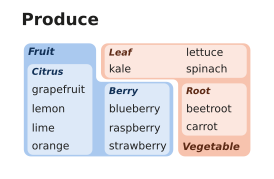

In [ ]:
produce = [dict(kind="Fruit", sub="Citrus", item=i) for i in ["lemon", "lime", "orange", "grapefruit"]] + \
          [dict(kind="Fruit", sub="Berry", item=i) for i in ["strawberry", "blueberry", "raspberry"]] + \
          [dict(kind="Vegetable", sub="Root", item=i) for i in ["carrot", "beetroot"]] + \
          [dict(kind="Vegetable", sub="Leaf", item=i) for i in ["spinach", "lettuce", "kale"]]
treemap.plot(produce, levels=["kind", "sub"], name="item", title="Produce")

Save the figure by giving a file name; the format follows the extension. In SVG and PDF the
names stay as text you can edit:

In [ ]:
tmp = Path(tempfile.mkdtemp())
treemap.plot(produce, levels=["kind", "sub"], name="item", out=tmp/"produce.svg")
assert ">grapefruit</text>" in (tmp/"produce.svg").read_text()

## Options

**Header text.** `labels` maps group names to shorter headers. If a header must go on two lines,
a soft hyphen (`"­"`) inside a word marks where it may break; it is invisible otherwise.

**Small groups.** `min_group=3` pools subgroups with fewer than three items into one "other"
subgroup. `last=("Other", ...)` puts the named groups at the end; otherwise groups go largest
first.

**Slant.** Gene names follow different rules in different organisms (bacterial genes are
italic, human protein symbols are not), so the slant is yours to set: `item_style="italic"`, or a
function giving each name its own, such as italic gene symbols with roman locus tags. Headers
take the opposite slant to most names unless you set `header_style`.

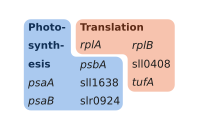

In [ ]:
import re
genes = [dict(process="Photosynthesis", gene=g) for g in ["psaA", "psaB", "psbA", "sll1638", "slr0924"]] + \
        [dict(process="Translation", gene=g) for g in ["rplA", "rplB", "tufA", "sll0408"]]
locus = re.compile(r"^s[ls][lr]\d{4}$")    # Synechocystis locus tags stay roman
treemap.plot(genes, levels="process", name="gene",
             item_style=lambda it: "normal" if locus.match(it.name) else "italic")

**Fonts.** The default is matplotlib's DejaVu Sans; `font="Inter"` (or any installed font)
changes it. `fontsize` sets the names' size; headers follow it.

**Shape.** `target_aspect` is the width-to-height ratio to aim for (default 1.6).

## Checking a layout

Every layout keeps the same guarantees, and `check_layout` reports them:

In [ ]:
lay = treemap.plot(**treemap.load_example("countries"))
treemap.check_layout(lay)

{'Every item placed once': True,
 'One cell per item and header cell': True,
 'Each group is one piece': True,
 'Each header is one block of its size': True,
 'All cells on the grid': True}

In [ ]:
#| hide
assert all(treemap.check_layout(lay).values())
assert all(treemap.check_layout(treemap.plot(**treemap.load_example("ddx6"))).values())